In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os


In [109]:
data = pd.read_csv("données/LucasBenjamin_664b368abdac8e709d4ff17d.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,104926.0,external-consent.html,external-html,104963,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,110103,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7606.0,NaN,survey-dropdown,117714,0.0-2.0,NaN,"{""0"":""40-60"",""1"":""F""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,7761.0,NaN,survey-text,125477,0.0-3.0,NaN,"{""Q0"":""664b368abdac8e709d4ff17d""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,18879.0,NaN,instructions,144357,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":5755},{""page_i...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
296,NaN,NaN,lb-SeqAns-visual,4125607,0.0-224.0,NaN,NaN,NaN,1926.0,NaN,Stims/Gabor_img/Gabor_0.png,"56.5197900647,3.0278420081,-2.214661299,36.755...","-45,45,45,0,0",NaN,38.573972,0.0,33.977390,10.0,NaN
297,NaN,NaN,lb-SeqAns-visual,4130687,0.0-225.0,NaN,NaN,NaN,2042.0,NaN,Stims/Gabor_img/Gabor_0.png,141.1909200644,45,NaN,-16.352384,0.0,6.190920,4.0,NaN
298,NaN,NaN,lb-SeqAns-visual,4140375,0.0-226.0,NaN,NaN,NaN,3596.0,NaN,Stims/Gabor_img/Gabor_0.png,"-54.8690645717,-18.8366048256,-1.4063576751","45,0,0",NaN,-2.583021,0.0,169.963310,8.0,NaN


## Filtering du dataframe pour 1 sujet

In [3]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered = df_filtered.dropna(subset=["final_angle"])


In [4]:
df_filtered

,trial_rt,presented_angles,stimulus_rotations,final_angle,target,score
0,2305.0,"[186.3297408056, 172.4988425288, 115.6656248854]","[-45.0, -45.0, 45.0]",-24.646771,143.138643,6
1,1958.0,"[98.0630303799, 193.2006295208, 49.6275131924,...","[45.0, -45.0, 45.0, -45.0, 0.0, -45.0, -45.0]",-13.958290,132.662918,0
2,2380.0,"[34.0026636518, 78.5751250026, 144.2219944684,...","[45.0, 45.0, 0.0, 0.0, 0.0]",146.390631,130.568813,6
3,1969.0,"[86.8257191556, 137.819327054, 157.3072000846]","[0.0, -45.0, -45.0]",52.776429,97.281009,0
4,1735.0,"[99.1813592646, 91.1827684021, -22.5187808445,...","[-45.0, -45.0, 45.0, 0.0, 45.0, -45.0, -45.0]",209.237852,31.195139,10
...,...,...,...,...,...,...
195,2426.0,[218.4099821053],[-45.0],-9.130176,173.409982,10
196,2508.0,[195.9147529961],[0.0],15.718573,15.914753,10
197,1822.0,"[159.3437590786, 153.8696178772, 90.66764952, ...","[-45.0, -45.0, 0.0, 0.0, 0.0]",-79.343152,105.643527,10
198,1814.0,[74.993424937],[-45.0],-59.349332,29.993425,0


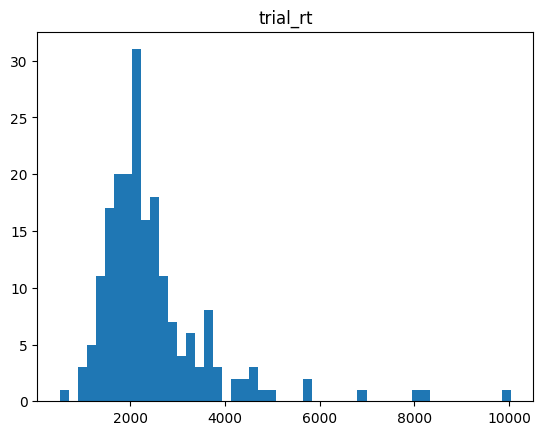

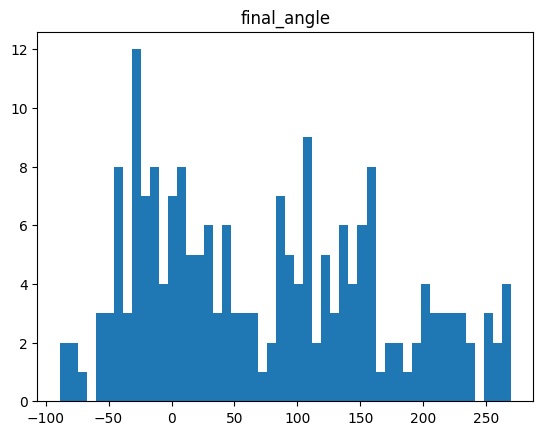

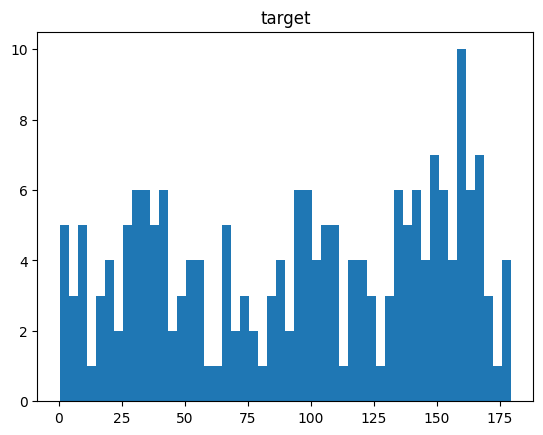

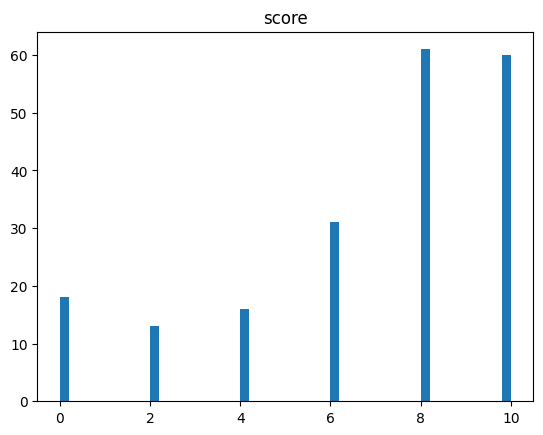

In [5]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

## Filtrage des données pour tous

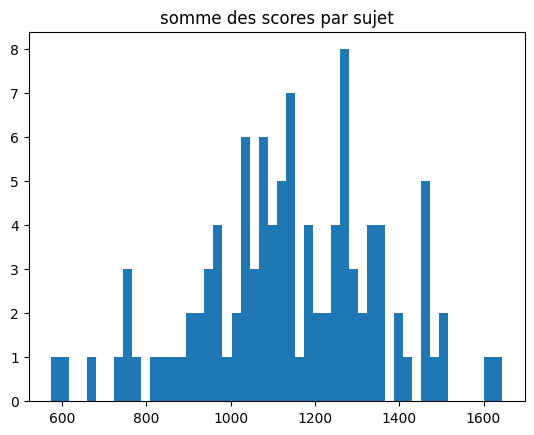

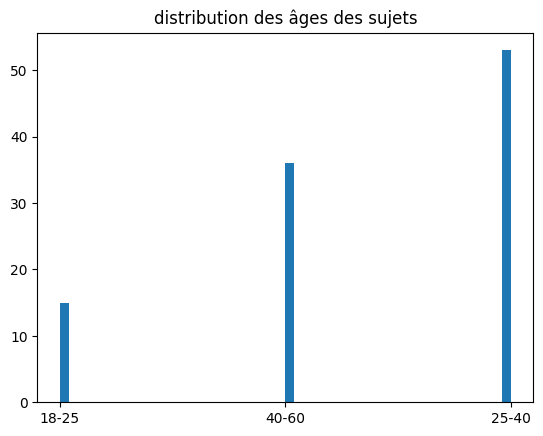

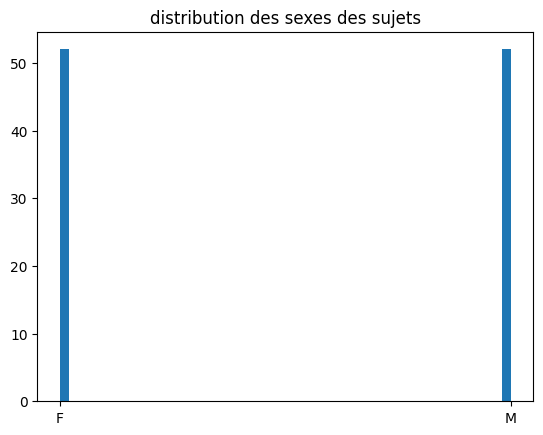

In [54]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sexe_tot = []
    for dfs in dfs :     
        age = dfs['responses'][dfs["trial_type"]== 'survey-dropdown'][2][6:11]
        sexe = dfs['responses'][dfs["trial_type"]== 'survey-dropdown'][2][18]
        age_tot = age_tot + [age]
        sexe_tot = sexe_tot + [sexe]
        
        df_filtered = dfs[dfs["stimulus_rotations"].notna()]
        df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
        df_filtered.reset_index(drop=True, inplace=True)
        df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['score'] = df_filtered['score'].astype(int)
        df_filtered = df_filtered.dropna(subset=["final_angle"])
        score_sum.append(df_filtered["score"].sum())
        
    return score_sum, age, age_tot, sexe, sexe_tot


plt.hist(data_sujets(dfs)[0], bins=50)
plt.title("somme des scores par sujet")
plt.show()

plt.hist(data_sujets(dfs)[2], bins=50)
plt.title("distribution des âges des sujets")
plt.show()

plt.hist(data_sujets(dfs)[4], bins=50)
plt.title(f"distribution des sexes des sujets ()")
plt.show()

In [68]:
print("il y a",data_sujets(dfs)[4].count('F'), "femmes")
print("il y a",data_sujets(dfs)[4].count('M'), 'hommes')

il y a 52 femmes
il y a 52 hommes


In [70]:
print("il y a",data_sujets(dfs)[2].count('18-25'), "personnes qui ont entre 18 et 25 ans")
print("il y a",data_sujets(dfs)[2].count('25-40'), 'personnes qui ont entre 25 et 40 ans')
print("il y a",data_sujets(dfs)[2].count('40-60'), 'personnes qui ont entre 40 et 60 ans')

il y a 15 personnes qui ont entre 18 et 25 ans
il y a 53 personnes qui ont entre 25 et 40 ans
il y a 36 personnes qui ont entre 40 et 60 ans


## dispositoin des angles sur un cercle

In [106]:
def wrap_angle(angle):
    return angle % 180

In [107]:
angle_sujets = wrap_angle(df_filtered['final_angle'].values)

targets = wrap_angle(df_filtered['target'].values)


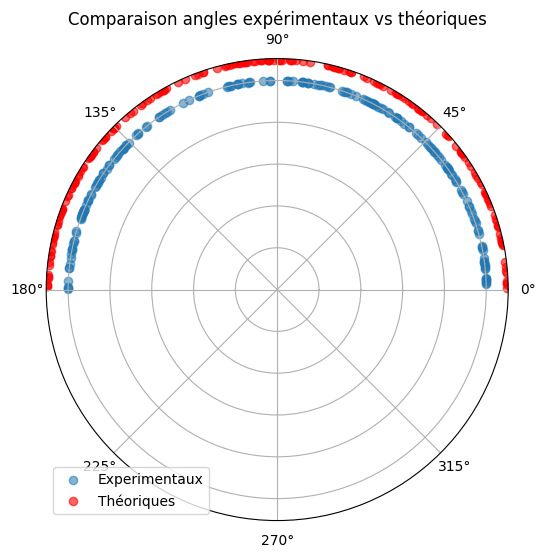

In [108]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

# angles en radians
theta_presented = np.deg2rad(angle_sujets)
theta_targets = np.deg2rad(targets)

# rayon arbitraire (juste pour séparer les couches)
ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])
ax.set_title("Comparaison angles expérimentaux vs théoriques")

ax.legend()
plt.show()


In [ ]:
angle_sujets = wrap_angle(df_filtered['final_angle'].values)

targets = wrap_angle(df_filtered['target'].values)
ç

In [ ]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

# angles en radians
theta_presented = np.deg2rad(angle_sujets)
theta_targets = np.deg2rad(targets)

# rayon arbitraire (juste pour séparer les couches)
ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])
ax.set_title("Comparaison angles expérimentaux vs théoriques")

ax.legend()
plt.show()


In [83]:
def circular_error(a, b):
    return ((a - b + 180) % 360) - 180

errors = circular_error(
    wrap_angle(df_filtered['final_angle'].values),
    wrap_angle(df_filtered['target'].values)
)


In [84]:
df_filtered

,trial_rt,presented_angles,stimulus_rotations,final_angle,target,score
0,2922.0,"[-3.0912938749, -16.9580510016, 13.4273621149]","[45.0, 45.0, 0.0]",23.164179,27.795279,10
1,2580.0,"[145.3202261314, 142.0681696315, 84.7800554298...","[0.0, 0.0, 45.0, 45.0, 45.0, -45.0, 0.0]",21.134240,160.500241,0
2,4301.0,"[135.4269436659, 69.6084742279, 107.1642506781]","[0.0, 45.0, 0.0]",131.606989,119.021751,6
3,6310.0,"[73.6761902031, 28.7147378745, 54.7920209909]","[45.0, 45.0, 45.0]",78.086976,97.458132,4
4,5313.0,"[35.7995928923, 30.831993453, 10.0712474876, -...","[-45.0, 0.0, 0.0, 45.0, -45.0]",179.268604,15.933681,6
...,...,...,...,...,...,...
195,2652.0,"[202.1896559288, 202.0151805443, 159.4817384062]","[-45.0, -45.0, -45.0]",167.471192,143.200700,2
196,2780.0,"[141.0696971221, 120.8180831235, 150.822708797...","[0.0, 45.0, 45.0, -45.0, 0.0]",148.266481,166.225685,6
197,2820.0,"[119.236972683, 217.2606920663, 199.5020981922]","[45.0, -45.0, -45.0]",-23.912318,163.668882,8
198,2944.0,[216.7223240683],[-45.0],-11.008202,171.722324,10


## implication des rotations dans la détermination des angles

In [94]:
def wrap_angle(angle):
    return angle % 360

start_angle = df_filtered['presented_angles'].apply(lambda x: x[-1])
rotation_sum = df_filtered['stimulus_rotations'].apply(np.sum)
expected_angle = wrap_angle(start_angle + rotation_sum)


In [95]:
def circular_error(a, b):
    return ((a - b + 180) % 360) - 180

df_filtered['rotation_error'] = circular_error(
    wrap_angle(df_filtered['final_angle']),
    expected_angle
)


Erreur = ce que le participant a répondu
− ce qu’il aurait dû répondre s’il appliquait parfaitement la rotation

Gros pic autour de 0°
➡️ Les gens font bien la rotation

Pics autour de ±45°
➡️ Les gens répondent comme s’il n’y avait pas de rotation

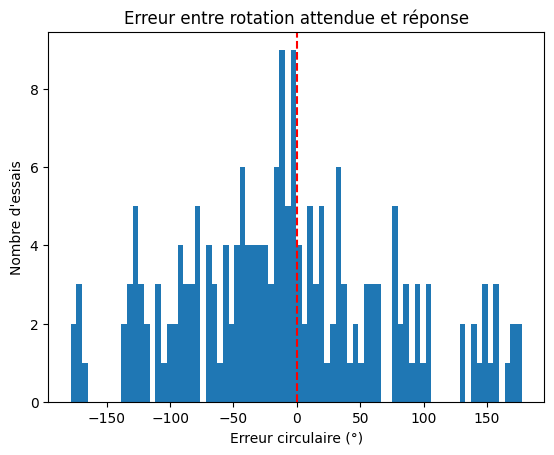

In [105]:
plt.hist(df_filtered['rotation_error'], bins=80)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("Erreur circulaire (°)")
plt.ylabel("Nombre d'essais")
plt.title("Erreur entre rotation attendue et réponse")
plt.show()


In [97]:
df_filtered['rotation_type'] = rotation_sum.map({
    -45: '-45',
     0: '0',
     45: '+45'
})


Est-ce que certaines rotations sont plus difficiles que d’autres ?

boîte centrée sur 0 → rotation bien faite

boîte décalée → biais systématique

boîte large → imprécision


0° : bien centré → OK

+45° : décalé vers −20° → sous-rotation

−45° : très dispersé → confus@

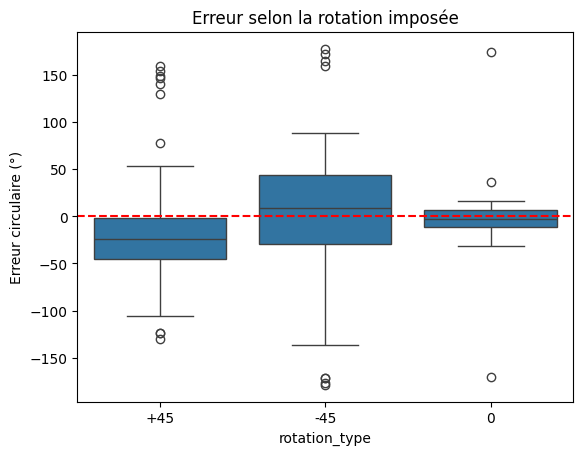

In [98]:
import seaborn as sns

sns.boxplot(
    x='rotation_type',
    y='rotation_error',
    data=df_filtered
)
plt.axhline(0, color='red', linestyle='--')
plt.ylabel("Erreur circulaire (°)")
plt.title("Erreur selon la rotation imposée")
plt.show()


Est-ce que rater la rotation fait baisser le score ?

Si + l’erreur augmente, plus le score chute, alors le score reflète la capacité à intégrer la rotation

Si il n'y a pas de relation, alors le score dépend d’autre chose (bruit perceptif, attention…)


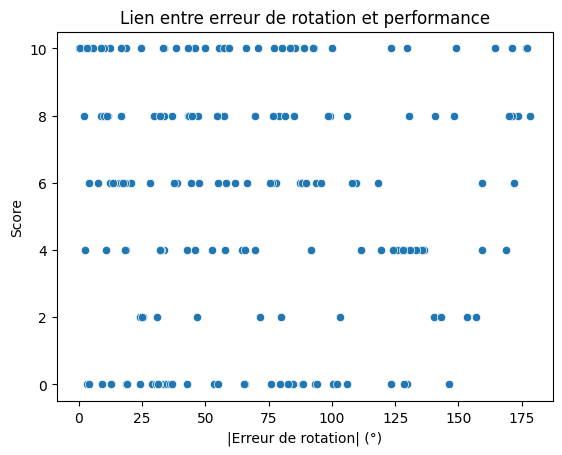

In [99]:
sns.scatterplot(
    x=np.abs(df_filtered['rotation_error']),
    y=df_filtered['score']
)
plt.xlabel("|Erreur de rotation| (°)")
plt.ylabel("Score")
plt.title("Lien entre erreur de rotation et performance")
plt.show()


➡️ Pas de relation
➡️ Le score dépend d’autre chose (bruit perceptif, attention…)

In [100]:
df_filtered[['rotation_error', 'score']].corr()


,rotation_error,score
rotation_error,1.000000,-0.028993
score,-0.028993,1.000000


In [101]:
df_filtered['final_rel_target'] = circular_error(
    df_filtered['final_angle'],
    df_filtered['target']
)


Les gens répondent-ils toujours autour de la target
ou bien la rotation déforme systématiquement leur réponse ?

toutes les boîtes centrées sur 0
→ target bien représentée, rotation intégrée

boîtes décalées selon la rotation
→ la rotation crée un biais cognitif


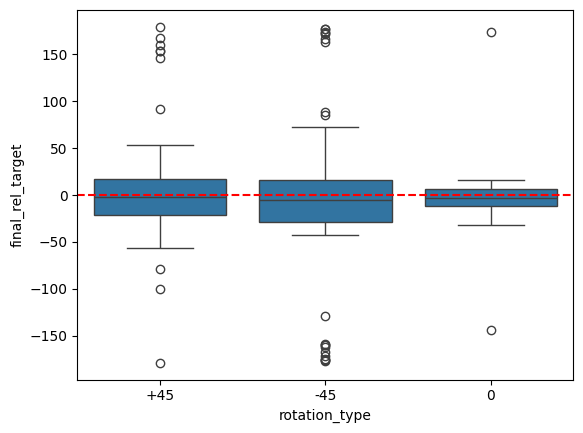

In [102]:
sns.boxplot(
    x='rotation_type',
    y='final_rel_target',
    data=df_filtered
)
plt.axhline(0, color='red', linestyle='--')
plt.show()


toutes les boîtes centrées sur 0
→ target bien représentée, rotation intégrée

boîtes décalées selon la rotation
→ la rotation crée un biais cognitif